In [1]:
import os
import urllib.request

CSV_YOLU = "data/advertising.csv"
URL = "https://www.statlearning.com/s/Advertising.csv"

if not os.path.exists(CSV_YOLU):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(URL, CSV_YOLU)
    print("Veri seti indirildi.")
else:
    print("Veri seti mevcut:", CSV_YOLU)

Veri seti mevcut: data/advertising.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", palette="Set2")
%matplotlib inline

df = pd.read_csv(CSV_YOLU, index_col=0)
print("Veri seti başarıyla yüklendi.")
df.head(10)

Veri seti başarıyla yüklendi.


,TV,radio,newspaper,sales
1,230.1000,37.8000,69.2000,22.1000
2,44.5000,39.3000,45.1000,10.4000
3,17.2000,45.9000,69.3000,9.3000
4,151.5000,41.3000,58.5000,18.5000
5,180.8000,10.8000,58.4000,12.9000
6,8.7000,48.9000,75.0000,7.2000
7,57.5000,32.8000,23.5000,11.8000
8,120.2000,19.6000,11.6000,13.2000
9,8.6000,2.1000,1.0000,4.8000
10,199.8000,2.6000,21.2000,10.6000


In [3]:
df.tail()

,TV,radio,newspaper,sales
196,38.2000,3.7000,13.8000,7.6000
197,94.2000,4.9000,8.1000,9.7000
198,177.0000,9.3000,6.4000,12.8000
199,283.6000,42.0000,66.2000,25.5000
200,232.1000,8.6000,8.7000,13.4000


In [4]:
print(f"Gözlem sayısı  : {df.shape[0]}")
print(f"Değişken sayısı: {df.shape[1]}")
print()
df.info()

Gözlem sayısı  : 200
Değişken sayısı: 4

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [5]:
YANIT = "sales"
ACIKLAYICI = ["TV", "radio", "newspaper"]

pd.DataFrame({
    "Eksik Sayısı": df.isna().sum(),
    "Benzersiz Değer": df.nunique(),
    "Sıfır Değer Sayısı": (df == 0).sum(),
})

,Eksik Sayısı,Benzersiz Değer,Sıfır Değer Sayısı
TV,0,190,0
radio,0,167,1
newspaper,0,172,0
sales,0,121,0


In [6]:
print("Tekrarlanan satır sayısı:", df.duplicated().sum())

Tekrarlanan satır sayısı: 0


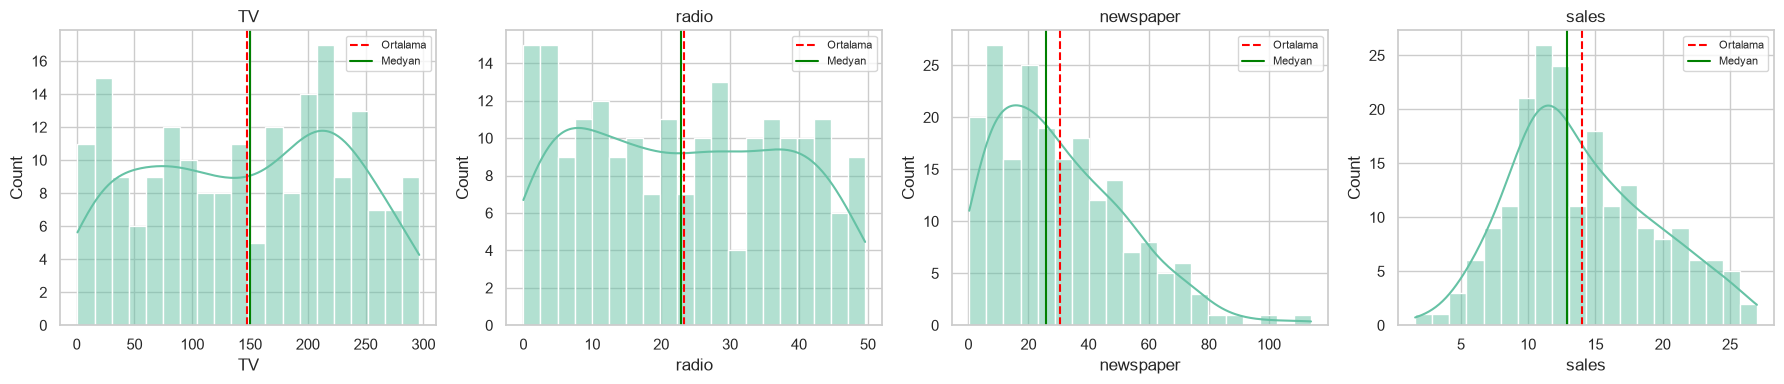

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, kol in zip(axes, df.columns):
    sns.histplot(df[kol], kde=True, ax=ax, bins=20)
    ax.axvline(df[kol].mean(), color="red", linestyle="--", label="Ortalama")
    ax.axvline(df[kol].median(), color="green", label="Medyan")
    ax.set_title(kol)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

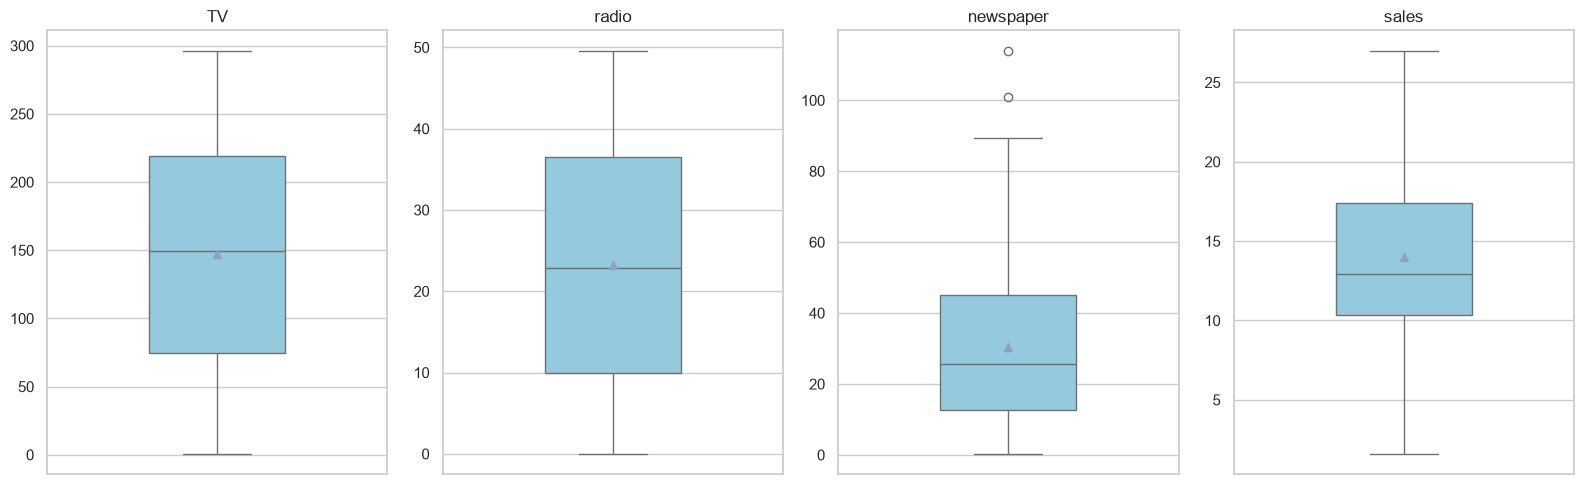

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, kol in zip(axes, df.columns):
    sns.boxplot(y=df[kol], ax=ax, color="skyblue", width=0.4, showmeans=True)
    ax.set_title(kol)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [9]:
q1, q3 = df["newspaper"].quantile([0.25, 0.75])
df[df["newspaper"] > q3 + 1.5 * (q3 - q1)]

,TV,radio,newspaper,sales
17,67.8000,36.6000,114.0000,12.5000
102,296.4000,36.3000,100.9000,23.8000


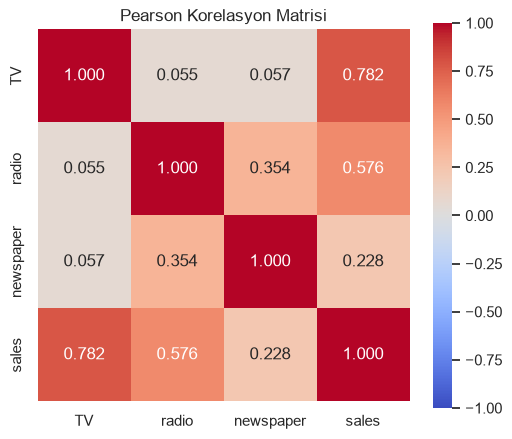

In [10]:
korelasyon = df.corr()
plt.figure(figsize=(6, 5))
sns.heatmap(korelasyon, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Pearson Korelasyon Matrisi")
plt.show()

In [11]:
kor_test = []
for kol in ACIKLAYICI:
    r, p = stats.pearsonr(df[kol], df[YANIT])
    kor_test.append({"Değişken": kol, "r (sales ile)": r, "p-değeri": p})
pd.DataFrame(kor_test).set_index("Değişken")

,r (sales ile),p-değeri
Değişken,,
TV,0.7822,0.0000
radio,0.5762,0.0000
newspaper,0.2283,0.0011


In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
TV,200.0000,147.0425,85.8542,0.7000,74.3750,149.7500,218.8250,296.4000
radio,200.0000,23.2640,14.8468,0.0000,9.9750,22.9000,36.5250,49.6000
newspaper,200.0000,30.5540,21.7786,0.3000,12.7500,25.7500,45.1000,114.0000
sales,200.0000,14.0225,5.2175,1.6000,10.3750,12.9000,17.4000,27.0000


In [13]:
def aciklayici_tablo(d):
    satirlar = {}
    for kol in d.columns:
        s = d[kol]
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        ga = stats.t.interval(0.95, len(s) - 1, loc=s.mean(), scale=stats.sem(s))
        satirlar[kol] = {
            "n": s.count(),
            "Toplam": s.sum(),
            "Ortalama": s.mean(),
            "Medyan": s.median(),
            "Mod": s.mode().iloc[0],
            "Std. Sapma": s.std(),
            "Varyans": s.var(),
            "Std. Hata": stats.sem(s),
            "Değişim Kats. (%)": s.std() / s.mean() * 100,
            "Minimum": s.min(),
            "Q1": q1,
            "Q3": q3,
            "Maksimum": s.max(),
            "Açıklık": s.max() - s.min(),
            "IQR": iqr,
            "Çarpıklık": s.skew(),
            "Basıklık": s.kurt(),
            "Aykırı (1.5·IQR)": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
            "%95 GA Alt": ga[0],
            "%95 GA Üst": ga[1],
        }
    return pd.DataFrame(satirlar)

aciklayici_tablo(df)

,TV,radio,newspaper,sales
n,200.0000,200.0000,200.0000,200.0000
Toplam,29408.5000,4652.8000,6110.8000,2804.5000
Ortalama,147.0425,23.2640,30.5540,14.0225
Medyan,149.7500,22.9000,25.7500,12.9000
Mod,17.2000,4.1000,8.7000,9.7000
Std. Sapma,85.8542,14.8468,21.7786,5.2175
Varyans,7370.9499,220.4277,474.3083,27.2219
Std. Hata,6.0708,1.0498,1.5400,0.3689
Değişim Kats. (%),58.3874,63.8188,71.2791,37.2077
Minimum,0.7000,0.0000,0.3000,1.6000


In [14]:
normallik = []
for kol in df.columns:
    w, p = stats.shapiro(df[kol])
    normallik.append({"Değişken": kol, "Shapiro-Wilk W": w, "p-değeri": p,
                      "Normal mi? (α=0.05)": "Evet" if p > 0.05 else "Hayır"})
pd.DataFrame(normallik).set_index("Değişken")

,Shapiro-Wilk W,p-değeri,Normal mi? (α=0.05)
Değişken,,,
TV,0.9495,0.0000,Hayır
radio,0.9440,0.0000,Hayır
newspaper,0.9364,0.0000,Hayır
sales,0.9760,0.0017,Hayır


In [15]:
model_tam = smf.ols("sales ~ TV + radio + newspaper", data=df).fit()
print(model_tam.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           1.58e-96
Time:                        21:28:00   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9389      0.312      9.422      0.0

In [16]:
def katsayi_tablosu(m):
    ga = m.conf_int()
    return pd.DataFrame({
        "Katsayı (β)": m.params,
        "Std. Hata": m.bse,
        "t": m.tvalues,
        "p-değeri": m.pvalues,
        "%95 GA Alt": ga[0],
        "%95 GA Üst": ga[1],
        "Anlamlı mı? (α=0.05)": np.where(m.pvalues < 0.05, "Evet", "Hayır"),
    })

katsayi_tablosu(model_tam)

,Katsayı (β),Std. Hata,t,p-değeri,%95 GA Alt,%95 GA Üst,Anlamlı mı? (α=0.05)
Intercept,2.9389,0.3119,9.4223,0.0000,2.3238,3.5540,Evet
TV,0.0458,0.0014,32.8086,0.0000,0.0430,0.0485,Evet
radio,0.1885,0.0086,21.8935,0.0000,0.1715,0.2055,Evet
newspaper,-0.0010,0.0059,-0.1767,0.8599,-0.0126,0.0105,Hayır


In [17]:
b = model_tam.params
print("Tam model regresyon denklemi:")
print(f"  sales = {b['Intercept']:.4f} {b['TV']:+.4f}·TV {b['radio']:+.4f}·radio {b['newspaper']:+.4f}·newspaper")

Tam model regresyon denklemi:
  sales = 2.9389 +0.0458·TV +0.1885·radio -0.0010·newspaper


In [18]:
X = df[ACIKLAYICI].values
y = df[YANIT].values

X_mat = np.column_stack([np.ones(len(X)), X])
beta = np.linalg.inv(X_mat.T @ X_mat) @ X_mat.T @ y

sk = LinearRegression().fit(X, y)

pd.DataFrame({
    "statsmodels": model_tam.params.values,
    "(XᵀX)⁻¹Xᵀy": beta,
    "scikit-learn": np.r_[sk.intercept_, sk.coef_],
}, index=["β0 (sabit)", "β1 (TV)", "β2 (radio)", "β3 (newspaper)"])

,statsmodels,(XᵀX)⁻¹Xᵀy,scikit-learn
β0 (sabit),2.9389,2.9389,2.9389
β1 (TV),0.0458,0.0458,0.0458
β2 (radio),0.1885,0.1885,0.1885
β3 (newspaper),-0.0010,-0.0010,-0.0010


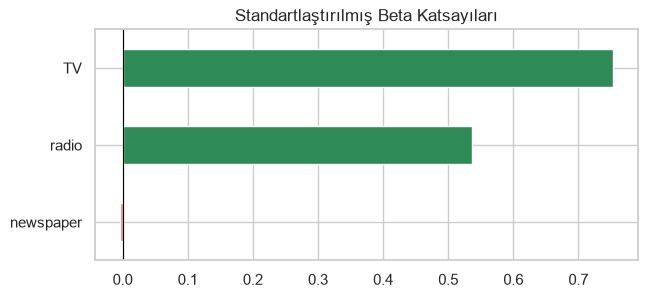

,Standart β
TV,0.7531
radio,0.5365
newspaper,-0.0043


In [19]:
z = (df - df.mean()) / df.std()
std_beta = smf.ols("sales ~ TV + radio + newspaper", data=z).fit().params.drop("Intercept")

ax = std_beta.sort_values().plot.barh(figsize=(7, 3), color=["lightcoral", "seagreen", "seagreen"])
ax.set_title("Standartlaştırılmış Beta Katsayıları")
ax.axvline(0, color="black", linewidth=0.8)
plt.show()
std_beta.to_frame("Standart β")

In [20]:
X_vif = sm.add_constant(df[ACIKLAYICI])
pd.DataFrame({
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])]
}, index=ACIKLAYICI)

,VIF
TV,1.0046
radio,1.1450
newspaper,1.1452


In [21]:
model = smf.ols("sales ~ TV + radio", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     859.6
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           4.83e-98
Time:                        21:28:00   Log-Likelihood:                -386.20
No. Observations:                 200   AIC:                             778.4
Df Residuals:                     197   BIC:                             788.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9211      0.294      9.919      0.0

In [22]:
katsayi_tablosu(model)

,Katsayı (β),Std. Hata,t,p-değeri,%95 GA Alt,%95 GA Üst,Anlamlı mı? (α=0.05)
Intercept,2.9211,0.2945,9.9192,0.0000,2.3403,3.5019,Evet
TV,0.0458,0.0014,32.9087,0.0000,0.0430,0.0485,Evet
radio,0.1880,0.0080,23.3824,0.0000,0.1721,0.2038,Evet


In [23]:
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
def cv_r2(degiskenler):
    return cross_val_score(LinearRegression(), df[degiskenler], df[YANIT], cv=kfold, scoring="r2").mean()

pd.DataFrame({
    "Tam model (TV + radio + newspaper)": [model_tam.rsquared, model_tam.rsquared_adj, np.sqrt(model_tam.mse_resid),
                                            model_tam.aic, model_tam.bic, cv_r2(ACIKLAYICI)],
    "İndirgenmiş model (TV + radio)": [model.rsquared, model.rsquared_adj, np.sqrt(model.mse_resid),
                                        model.aic, model.bic, cv_r2(["TV", "radio"])],
}, index=["R²", "Düzeltilmiş R²", "Std. Hata (RSE)", "AIC", "BIC", "10-katlı CV R²"])

,Tam model (TV + radio + newspaper),İndirgenmiş model (TV + radio)
R²,0.8972,0.8972
Düzeltilmiş R²,0.8956,0.8962
Std. Hata (RSE),1.6855,1.6814
AIC,780.3622,778.3941
BIC,793.5555,788.2891
10-katlı CV R²,0.8731,0.8749


In [24]:
anova_karsilastirma = sm.stats.anova_lm(model, model_tam)
anova_karsilastirma.index = ["İndirgenmiş (TV + radio)", "Tam (TV + radio + newspaper)"]
anova_karsilastirma

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
İndirgenmiş (TV + radio),197.0000,556.9140,0.0000,NaN,NaN,NaN
Tam (TV + radio + newspaper),196.0000,556.8253,1.0000,0.0887,0.0312,0.8599


In [25]:
b0, b1, b2 = model.params
print("Seçilen (indirgenmiş) model regresyon denklemi:")
print(f"  sales = {b0:.4f} {b1:+.4f}·TV {b2:+.4f}·radio")

Seçilen (indirgenmiş) model regresyon denklemi:
  sales = 2.9211 +0.0458·TV +0.1880·radio


In [26]:
y_tahmin = model.fittedvalues
R = np.corrcoef(y, y_tahmin)[0, 1]
R_tam = np.corrcoef(y, model_tam.fittedvalues)[0, 1]

def r_yorum(r):
    r = abs(r)
    if r >= 0.9: return "çok güçlü"
    if r >= 0.7: return "güçlü"
    if r >= 0.5: return "orta"
    if r >= 0.3: return "zayıf"
    return "çok zayıf"

print(f"R (indirgenmiş model, TV + radio)      : {R:.4f}   (√R² = {np.sqrt(model.rsquared):.4f})")
print(f"R (tam model, TV + radio + newspaper)  : {R_tam:.4f}")
print(f"Karşılaştırma — yalnızca TV ile r      : {df['TV'].corr(df['sales']):.4f}")
print()
print(f"R = {R:.4f} → model tahminleri ile gözlenen satışlar arasında {r_yorum(R)} bir ilişki vardır.")

R (indirgenmiş model, TV + radio)      : 0.9472   (√R² = 0.9472)
R (tam model, TV + radio + newspaper)  : 0.9472
Karşılaştırma — yalnızca TV ile r      : 0.7822

R = 0.9472 → model tahminleri ile gözlenen satışlar arasında çok güçlü bir ilişki vardır.


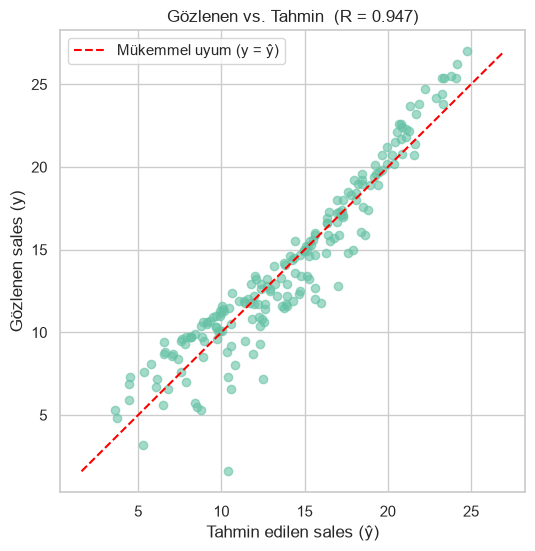

In [27]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_tahmin, y, alpha=0.6)
sinir = [min(y.min(), y_tahmin.min()), max(y.max(), y_tahmin.max())]
ax.plot(sinir, sinir, "r--", label="Mükemmel uyum (y = ŷ)")
ax.set_xlabel("Tahmin edilen sales (ŷ)")
ax.set_ylabel("Gözlenen sales (y)")
ax.set_title(f"Gözlenen vs. Tahmin  (R = {R:.3f})")
ax.legend()
plt.show()

In [28]:
artik = model.resid
pd.Series({
    "MAE (ortalama mutlak hata)": mean_absolute_error(y, y_tahmin),
    "RMSE": np.sqrt(mean_squared_error(y, y_tahmin)),
    "Std. hata (RSE)": np.sqrt(model.mse_resid),
    "Ortalama mutlak yüzde hata (%)": np.mean(np.abs(artik / y)) * 100,
    "F istatistiği": model.fvalue,
    "F testi p-değeri": model.f_pvalue,
    "Durbin-Watson": sm.stats.durbin_watson(artik),
    "Shapiro-Wilk p (artıklar)": stats.shapiro(artik).pvalue,
}).to_frame("Değer")

,Değer
MAE (ortalama mutlak hata),1.2537
RMSE,1.6687
Std. hata (RSE),1.6814
Ortalama mutlak yüzde hata (%),13.8843
F istatistiği,859.6177
F testi p-değeri,0.0000
Durbin-Watson,2.0808
Shapiro-Wilk p (artıklar),0.0000


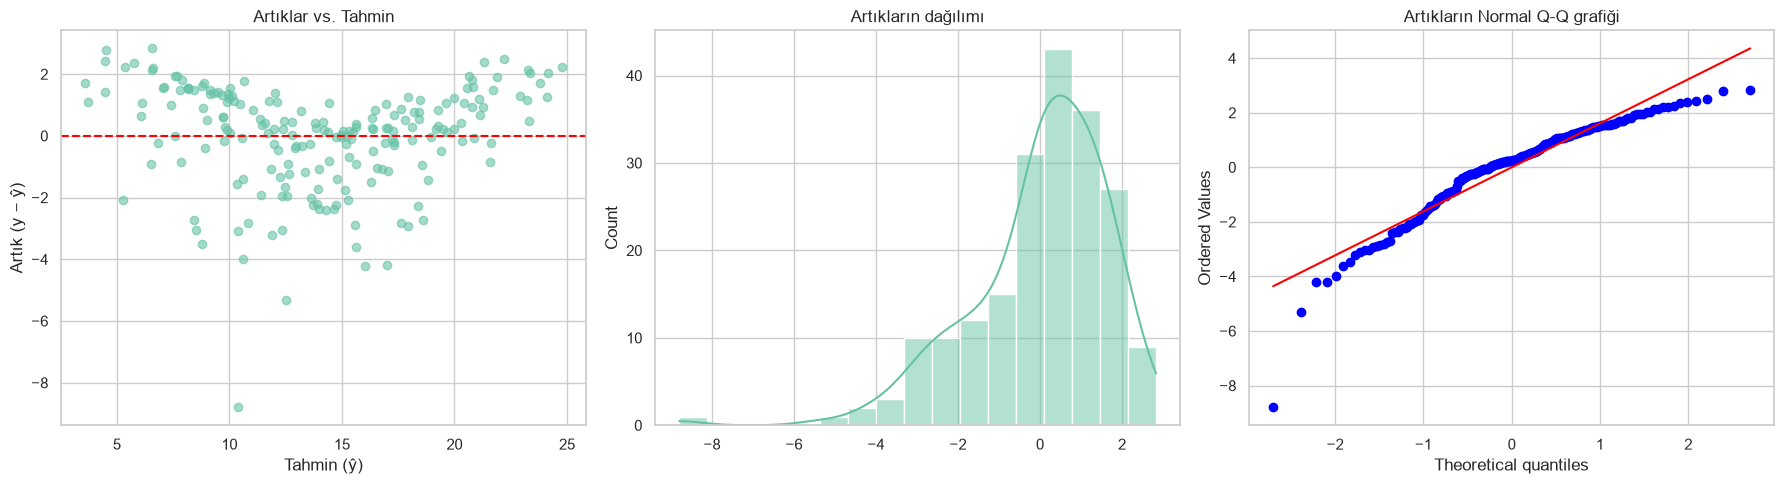

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(y_tahmin, artik, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Tahmin (ŷ)")
axes[0].set_ylabel("Artık (y − ŷ)")
axes[0].set_title("Artıklar vs. Tahmin")

sns.histplot(artik, kde=True, ax=axes[1])
axes[1].set_title("Artıkların dağılımı")

stats.probplot(artik, dist="norm", plot=axes[2])
axes[2].set_title("Artıkların Normal Q-Q grafiği")
plt.tight_layout()
plt.show()

In [30]:
n, p = len(y), 2
SST = np.sum((y - y.mean()) ** 2)
SSR = np.sum((y_tahmin - y.mean()) ** 2)
SSE = np.sum((y - y_tahmin) ** 2)
R2 = SSR / SST
R2_duz = 1 - (1 - R2) * (n - 1) / (n - p - 1)

print(f"SST (toplam değişim)        = {SST:,.4f}")
print(f"SSR (açıklanan değişim)     = {SSR:,.4f}")
print(f"SSE (açıklanamayan değişim) = {SSE:,.4f}")
print(f"SSR + SSE                   = {SSR + SSE:,.4f}")
print()
print(f"R² = SSR / SST      = {R2:.4f}")
print(f"R² = 1 − SSE / SST  = {1 - SSE / SST:.4f}")
print(f"R² (sklearn)        = {r2_score(y, LinearRegression().fit(df[['TV', 'radio']], y).predict(df[['TV', 'radio']])):.4f}")
print(f"Düzeltilmiş R²      = {R2_duz:.4f}")
print(f"Tam model R²        = {model_tam.rsquared:.4f}  (Düzeltilmiş: {model_tam.rsquared_adj:.4f})")
print()
print(f"→ TV ve radyo reklam harcamaları birlikte, satışlardaki toplam değişimin %{R2 * 100:.2f}'sini açıklamaktadır.")
print(f"→ Kalan %{(1 - R2) * 100:.2f}'lik değişim modelde yer almayan faktörlerden ve rastgele hatadan kaynaklanır.")

SST (toplam değişim)        = 5,417.1488
SSR (açıklanan değişim)     = 4,860.2348
SSE (açıklanamayan değişim) = 556.9140
SSR + SSE                   = 5,417.1487

R² = SSR / SST      = 0.8972
R² = 1 − SSE / SST  = 0.8972
R² (sklearn)        = 0.8972
Düzeltilmiş R²      = 0.8962
Tam model R²        = 0.8972  (Düzeltilmiş: 0.8956)

→ TV ve radyo reklam harcamaları birlikte, satışlardaki toplam değişimin %89.72'sini açıklamaktadır.
→ Kalan %10.28'lik değişim modelde yer almayan faktörlerden ve rastgele hatadan kaynaklanır.


In [31]:
anova = pd.DataFrame({
    "Kareler Toplamı": [SSR, SSE, SST],
    "Serbestlik Derecesi": [p, n - p - 1, n - 1],
}, index=["Regresyon", "Hata (Artık)", "Toplam"])
anova["Kareler Ortalaması"] = anova["Kareler Toplamı"] / anova["Serbestlik Derecesi"]
anova.loc["Toplam", "Kareler Ortalaması"] = np.nan
F = anova.loc["Regresyon", "Kareler Ortalaması"] / anova.loc["Hata (Artık)", "Kareler Ortalaması"]
anova.loc["Regresyon", "F"] = F
anova.loc["Regresyon", "p-değeri"] = stats.f.sf(F, p, n - p - 1)
print("ANOVA Tablosu")
anova

ANOVA Tablosu


,Kareler Toplamı,Serbestlik Derecesi,Kareler Ortalaması,F,p-değeri
Regresyon,4860.2348,2,2430.1174,859.6177,0.0000
Hata (Artık),556.9140,197,2.8270,NaN,NaN
Toplam,5417.1488,199,NaN,NaN,NaN


In [32]:
katki = []
for kol in ACIKLAYICI:
    digerleri = [k for k in ACIKLAYICI if k != kol]
    tek = smf.ols(f"sales ~ {kol}", data=df).fit().rsquared
    onsuz = smf.ols("sales ~ " + " + ".join(digerleri), data=df).fit().rsquared
    katki.append({"Değişken": kol, "Tek başına R²": tek, "Modele eklenince R² artışı": model_tam.rsquared - onsuz})
pd.DataFrame(katki).set_index("Değişken")

,Tek başına R²,Modele eklenince R² artışı
Değişken,,
TV,0.6119,0.5645
radio,0.3320,0.2514
newspaper,0.0521,0.0000


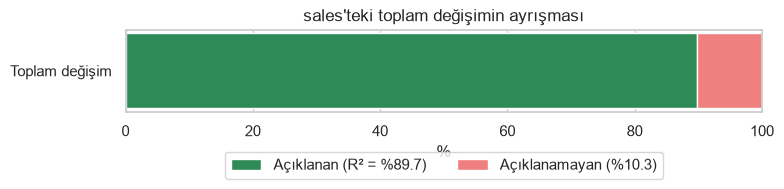

In [33]:
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.barh(["Toplam değişim"], [R2 * 100], color="seagreen", label=f"Açıklanan (R² = %{R2 * 100:.1f})")
ax.barh(["Toplam değişim"], [(1 - R2) * 100], left=[R2 * 100], color="lightcoral",
        label=f"Açıklanamayan (%{(1 - R2) * 100:.1f})")
ax.set_xlim(0, 100)
ax.set_xlabel("%")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.4), ncol=2)
ax.set_title("sales'teki toplam değişimin ayrışması")
plt.tight_layout()
plt.show()

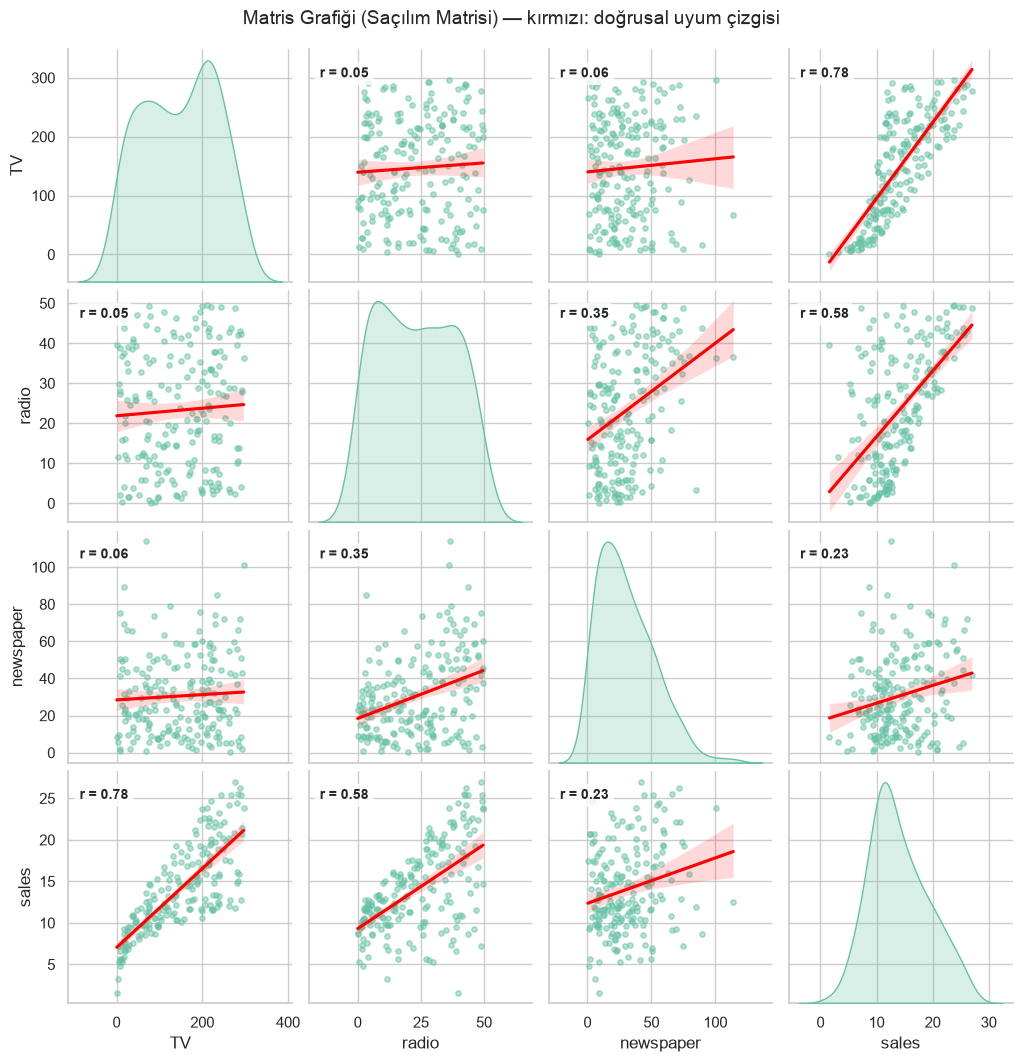

In [34]:
g = sns.pairplot(df, kind="reg", diag_kind="kde", height=2.6,
                 plot_kws={"scatter_kws": {"alpha": 0.5, "s": 15}, "line_kws": {"color": "red"}})
for i, sat in enumerate(df.columns):
    for j, sut in enumerate(df.columns):
        if i != j:
            g.axes[i, j].annotate(f"r = {df[sat].corr(df[sut]):.2f}", xy=(0.05, 0.88),
                                  xycoords="axes fraction", fontsize=10, fontweight="bold",
                                  bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
g.figure.suptitle("Matris Grafiği (Saçılım Matrisi) — kırmızı: doğrusal uyum çizgisi", y=1.02, fontsize=14)
plt.show()

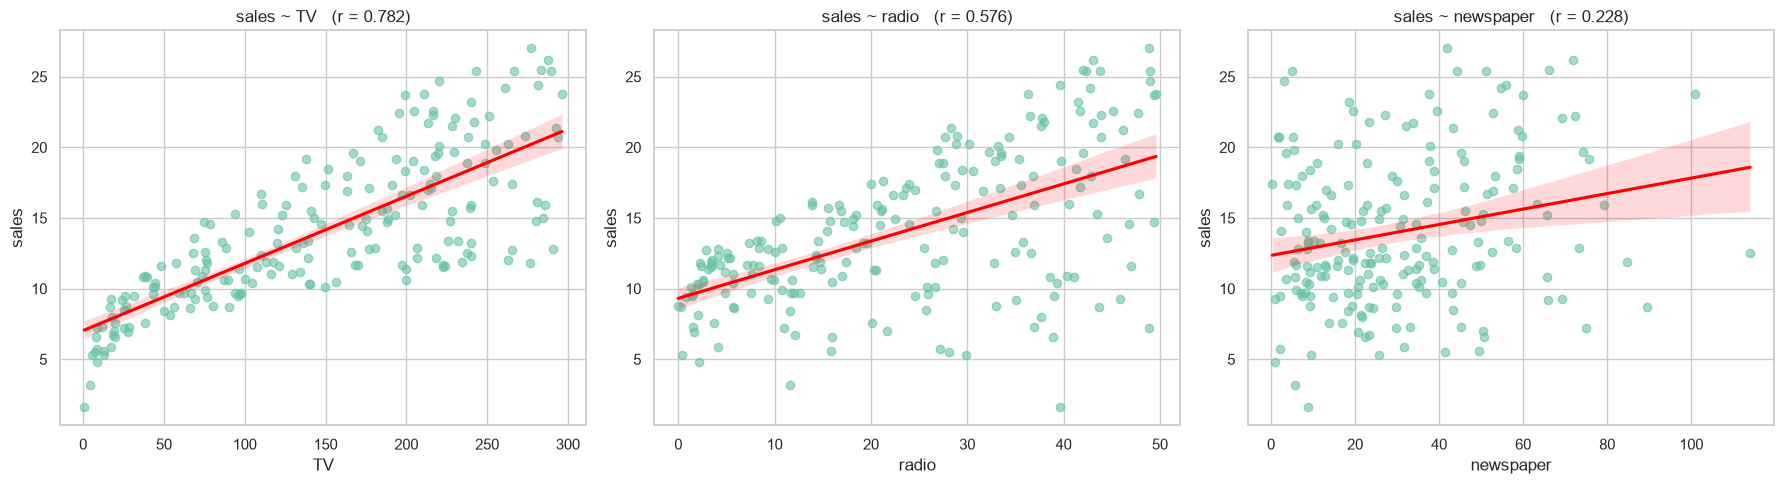

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, kol in zip(axes, ACIKLAYICI):
    sns.regplot(data=df, x=kol, y="sales", ax=ax, scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
    ax.set_title(f"sales ~ {kol}   (r = {df[kol].corr(df['sales']):.3f})")
plt.tight_layout()
plt.show()

In [36]:
def kismi_korelasyon(d, x, y, kontrol):
    rx = smf.ols(f"{x} ~ " + " + ".join(kontrol), data=d).fit().resid
    ry = smf.ols(f"{y} ~ " + " + ".join(kontrol), data=d).fit().resid
    return np.corrcoef(rx, ry)[0, 1]

pd.DataFrame({
    "Basit korelasyon (r)": [df[k].corr(df["sales"]) for k in ACIKLAYICI],
    "Kısmi korelasyon": [kismi_korelasyon(df, k, "sales", [d for d in ACIKLAYICI if d != k]) for k in ACIKLAYICI],
}, index=ACIKLAYICI)

,Basit korelasyon (r),Kısmi korelasyon
TV,0.7822,0.9198
radio,0.5762,0.8425
newspaper,0.2283,-0.0126


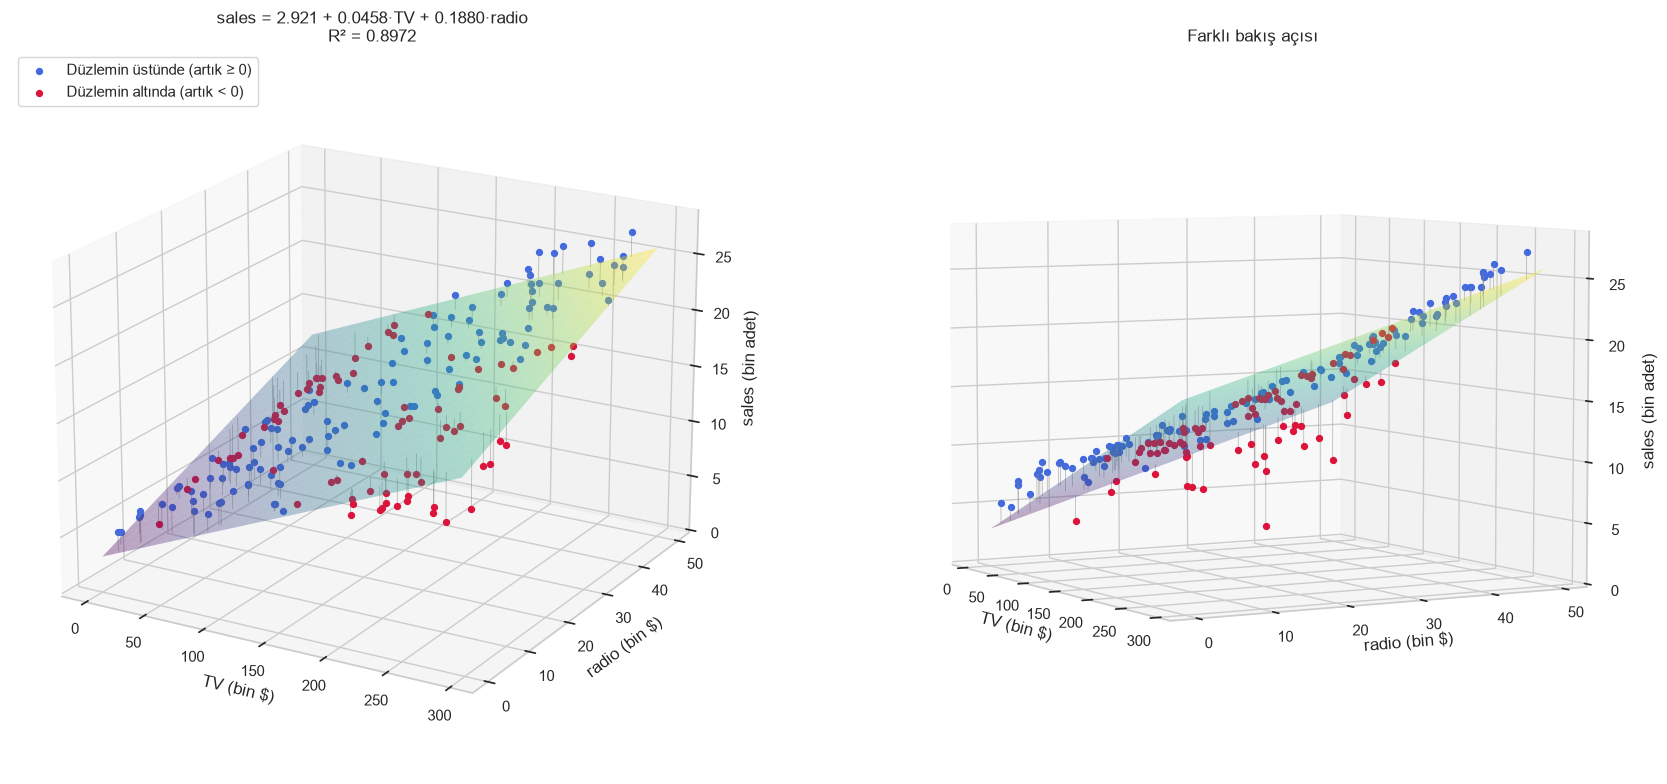

In [37]:
tv_izgara, radio_izgara = np.meshgrid(np.linspace(df["TV"].min(), df["TV"].max(), 30),
                                      np.linspace(df["radio"].min(), df["radio"].max(), 30))
sales_duzlem = b0 + b1 * tv_izgara + b2 * radio_izgara

def ciz_3d(ax, elev, azim):
    ust = artik >= 0
    ax.plot_surface(tv_izgara, radio_izgara, sales_duzlem, alpha=0.35, cmap="viridis", edgecolor="none")
    ax.scatter(df.loc[ust, "TV"], df.loc[ust, "radio"], df.loc[ust, "sales"], c="royalblue", s=18,
               depthshade=False, label="Düzlemin üstünde (artık ≥ 0)")
    ax.scatter(df.loc[~ust, "TV"], df.loc[~ust, "radio"], df.loc[~ust, "sales"], c="crimson", s=18,
               depthshade=False, label="Düzlemin altında (artık < 0)")
    for xi, yi, zi, zh in zip(df["TV"], df["radio"], df["sales"], y_tahmin):
        ax.plot([xi, xi], [yi, yi], [zi, zh], color="gray", linewidth=0.5, alpha=0.6)
    ax.set_xlabel("TV (bin $)")
    ax.set_ylabel("radio (bin $)")
    ax.set_zlabel("sales (bin adet)")
    ax.view_init(elev=elev, azim=azim)

fig = plt.figure(figsize=(18, 8))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ciz_3d(ax1, elev=20, azim=-60)
ax1.set_title(f"sales = {b0:.3f} + {b1:.4f}·TV + {b2:.4f}·radio\nR² = {R2:.4f}", fontsize=12)
ax1.legend(loc="upper left")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ciz_3d(ax2, elev=5, azim=-30)
ax2.set_title("Farklı bakış açısı", fontsize=12)
plt.tight_layout()
plt.show()

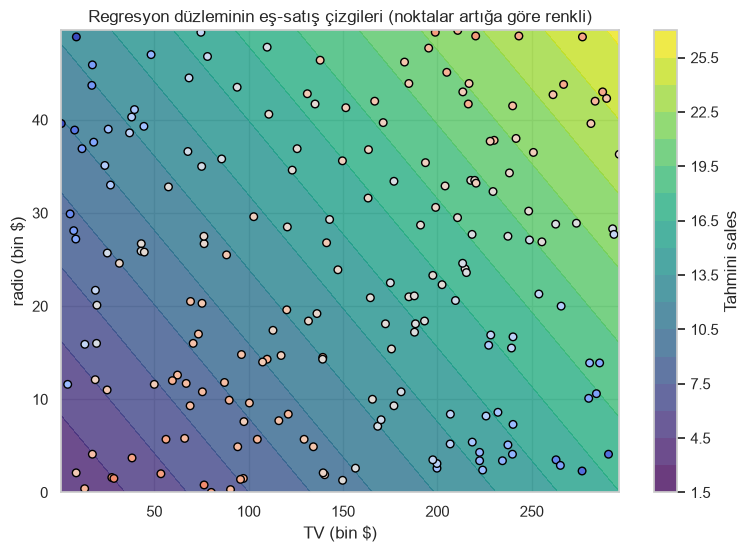

In [38]:
fig, ax = plt.subplots(figsize=(9, 6))
kontur = ax.contourf(tv_izgara, radio_izgara, sales_duzlem, levels=15, cmap="viridis", alpha=0.8)
plt.colorbar(kontur, label="Tahmini sales")
ax.scatter(df["TV"], df["radio"], c=artik, cmap="coolwarm", edgecolor="black", s=30, vmin=-5, vmax=5)
ax.set_xlabel("TV (bin $)")
ax.set_ylabel("radio (bin $)")
ax.set_title("Regresyon düzleminin eş-satış çizgileri (noktalar artığa göre renkli)")
plt.show()

In [39]:
yeni = pd.DataFrame({"TV": [50, 100, 150, 200, 250], "radio": [10, 20, 25, 30, 40]})
tahmin = model.get_prediction(yeni).summary_frame(alpha=0.05)
pd.concat([yeni, tahmin[["mean", "obs_ci_lower", "obs_ci_upper"]].rename(columns={
    "mean": "Tahmini sales", "obs_ci_lower": "%95 Tahmin Aralığı Alt", "obs_ci_upper": "%95 Tahmin Aralığı Üst"})], axis=1)

,TV,radio,Tahmini sales,%95 Tahmin Aralığı Alt,%95 Tahmin Aralığı Üst
0,50,10,7.0888,3.7484,10.4292
1,100,20,11.2565,7.9296,14.5833
2,150,25,14.4842,11.1600,17.8084
3,200,30,17.7119,14.3832,21.0406
4,250,40,21.8796,18.5342,25.2249


In [40]:
model_etk = smf.ols("sales ~ TV + radio + TV:radio", data=df).fit()
print(f"Etkileşimli model R²: {model_etk.rsquared:.4f}  (Düzeltilmiş: {model_etk.rsquared_adj:.4f})")
print(f"Etkileşim katsayısı : {model_etk.params['TV:radio']:.6f}  (p = {model_etk.pvalues['TV:radio']:.2e})")

Etkileşimli model R²: 0.9678  (Düzeltilmiş: 0.9673)
Etkileşim katsayısı : 0.001086  (p = 2.76e-51)
